In [ ]:
import torch
import torch.nn as nn
import numpy as np
import random
import cv2
from torchvision import transforms
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline 

# 1. SETUP
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = torch.load("0_dmid_mil_bags.pt", weights_only=False)
bags = data["bags"]     
labels = data["labels"]

print(f"Total Bags: {len(bags)}")

# 2. FEATURE EXTRACTOR: DINOv2 LARGE
print("Loading DINOv2 Large (vitl14)...")
dino_model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14').to(device)
dino_model.eval()

class CLAHE_Transform:
    def __call__(self, img_tensor):
        img_np = (img_tensor.squeeze().numpy() * 255).astype(np.uint8)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        img_eq = clahe.apply(img_np)
        return torch.tensor(img_eq).float().unsqueeze(0) / 255.0

base_transform = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(mean=(0.485,), std=(0.229,)) 
])

# 3. EXTRACT FEATURES (4-View TTA)
print("Extracting Features (This takes time)...")
X_data = []
y_data = []

clahe_pre = CLAHE_Transform()

with torch.no_grad():
    for i, bag in enumerate(bags):
        
        # 1. CLAHE Preprocessing
        bag_tensor = torch.tensor(np.array(bag, dtype=np.float32)).float()
        bag_clahe = torch.stack([clahe_pre(img) for img in bag_tensor])
        bag_gpu = bag_clahe.to(device).repeat(1, 3, 1, 1) 
        
        # 2. TTA: 4 Rotations
        feat_list = []
        for angle in [0, 90, 180, 270]:
            if angle == 0: img_rot = bag_gpu
            else: img_rot = transforms.functional.rotate(bag_gpu, angle)
            
            # Extract
            out = dino_model(base_transform(img_rot)) 
            feat_list.append(out)
        
        # Average Features (Noise Cancellation)
        features = torch.stack(feat_list).mean(dim=0) # (9, 1024)
        
        # AGGREGATION 
        # 1. Mean Pooling 
        feat_mean = torch.mean(features, dim=0)
        
        # 2. Top-K Pooling (K=2)
        # Using Top-2 is a sweet spot between Max (too noisy) and Mean (too diluted)
        k = min(2, features.size(0))
        feat_topk = torch.topk(features, k, dim=0)[0].mean(dim=0)
        
        combined = torch.cat([feat_mean, feat_topk]).cpu().numpy()
        
        X_data.append(combined)
        y_data.append(labels[i])

X_data = np.array(X_data)
y_data = np.array(y_data)

# 4. TRAIN WITH SMOTE + SVM
print("\nTraining with SMOTE + L1-SVM...")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

accs, aucs, senss, specs = [], [], [], []

for fold_i, (train_idx, val_idx) in enumerate(skf.split(X_data, y_data)):
    X_train, X_val = X_data[train_idx], X_data[val_idx]
    y_train, y_val = y_data[train_idx], y_data[val_idx]
    
    # PIPELINE
    pipe = ImbPipeline([
        ('smote', SMOTE(random_state=SEED, k_neighbors=3)), 
        ('scaler', StandardScaler()),
        # L1 Selection: We relax C to 0.05 to allow slightly more features
        ('selector', SelectFromModel(LinearSVC(penalty="l1", dual=False, C=0.05, random_state=SEED))), 
        ('svm', SVC(kernel='rbf', probability=True, class_weight=None, random_state=SEED))
    ])
    
    # Expanded Grid Search
    param_grid = {
        'svm__C': [1, 5, 10, 50],      
        'svm__gamma': ['scale', 0.001]
    }
    
    grid = GridSearchCV(pipe, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    
    # THRESHOLD TUNING 
    y_prob = best_model.predict_proba(X_val)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_val, y_prob)
    
    J = tpr - fpr
    best_ix = np.argmax(J)
    best_thresh = thresholds[best_ix]
    
    y_pred_opt = (y_prob >= best_thresh).astype(int)
    
    # Metrics
    acc = accuracy_score(y_val, y_pred_opt)
    try: auc = roc_auc_score(y_val, y_prob)
    except: auc = 0.5
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_opt).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    accs.append(acc)
    aucs.append(auc)
    senss.append(sens)
    specs.append(spec)
    
    n_features = np.sum(best_model.named_steps['selector'].get_support())
    print(f"Fold {fold_i+1} | Feats: {n_features} | Thresh: {best_thresh:.3f} | Acc: {acc:.3f} | AUC: {auc:.3f}")

# 5. FINAL REPORT
print("\n=== FINAL SMOTE RESULTS ===")
print(f"Average Accuracy:    {np.mean(accs):.3f}")
print(f"Average AUC:         {np.mean(aucs):.3f}")
print(f"Average Sensitivity: {np.mean(senss):.3f}")
print(f"Average Specificity: {np.mean(specs):.3f}")

Total Bags: 257
Loading DINOv2 Large (vitl14)...


Using cache found in /home/linux-hasan/.cache/torch/hub/facebookresearch_dinov2_main


Extracting Features (This takes time)...

Training with SMOTE + L1-SVM...
Fold 1 | Feats: 63 | Thresh: 0.574 | Acc: 0.846 | AUC: 0.884
Fold 2 | Feats: 62 | Thresh: 0.649 | Acc: 0.808 | AUC: 0.865
Fold 3 | Feats: 53 | Thresh: 0.406 | Acc: 0.745 | AUC: 0.728
Fold 4 | Feats: 51 | Thresh: 0.036 | Acc: 0.745 | AUC: 0.823
Fold 5 | Feats: 52 | Thresh: 0.405 | Acc: 0.902 | AUC: 0.948

=== FINAL SMOTE RESULTS ===
Average Accuracy:    0.809
Average AUC:         0.849
Average Sensitivity: 0.851
Average Specificity: 0.772


# 2nd best one

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import random
import cv2
from torchvision import transforms
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline 

# 1. SETUP
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = torch.load("0_dmid_mil_bags.pt", weights_only=False)
bags = data["bags"]     
labels = data["labels"]

print(f"Total Bags: {len(bags)}")

# 2. FEATURE EXTRACTOR (DINOv2 Large)
if 'dino_model' not in locals():
    print("Loading DINOv2 Large...")
    dino_model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14').to(device)
    dino_model.eval()

class CLAHE_Transform:
    def __call__(self, img_tensor):
        img_np = (img_tensor.squeeze().numpy() * 255).astype(np.uint8)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        img_eq = clahe.apply(img_np)
        return torch.tensor(img_eq).float().unsqueeze(0) / 255.0

base_transform = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(mean=(0.485,), std=(0.229,)) 
])

# 3. EXTRACT FEATURES
if 'X_data' not in locals() or X_data.shape[1] != 3072:
    print("Extracting Extended Features (Mean + TopK + Std)...")
    X_data = []
    y_data = []
    clahe_pre = CLAHE_Transform()

    with torch.no_grad():
        for i, bag in enumerate(bags):
            # Preprocessing
            bag_tensor = torch.tensor(np.array(bag, dtype=np.float32)).float()
            bag_clahe = torch.stack([clahe_pre(img) for img in bag_tensor])
            bag_gpu = bag_clahe.to(device).repeat(1, 3, 1, 1) 
            
            # TTA (4 Rotations)
            feat_list = []
            for angle in [0, 90, 180, 270]:
                if angle == 0: img_rot = bag_gpu
                else: img_rot = transforms.functional.rotate(bag_gpu, angle)
                feat_list.append(dino_model(base_transform(img_rot)))
            
            features = torch.stack(feat_list).mean(dim=0) # (9, 1024)
            
            # AGGREGATION (3072 dims) 
            feat_mean = torch.mean(features, dim=0)
            k = min(2, features.size(0))
            feat_topk = torch.topk(features, k, dim=0)[0].mean(dim=0)
            feat_std = torch.std(features, dim=0)
            
            combined = torch.cat([feat_mean, feat_topk, feat_std]).cpu().numpy()
            
            X_data.append(combined)
            y_data.append(labels[i])

    X_data = np.array(X_data)
    y_data = np.array(y_data)
    print(f"Data Shape: {X_data.shape}")
else:
    print(f"Using existing data: {X_data.shape}")

# 4. TRAIN: PCA + SMOTE + SVM
print("\nTraining Optimized PCA Pipeline...")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

accs, aucs, senss, specs = [], [], [], []

for fold_i, (train_idx, val_idx) in enumerate(skf.split(X_data, y_data)):
    X_train, X_val = X_data[train_idx], X_data[val_idx]
    y_train, y_val = y_data[train_idx], y_data[val_idx]
    
    #  PIPELINE 
    # 1. PowerTransformer: Fix skewed distribution 
    # 2. PCA: Compress 3072 dims -> Keep 98% Variance (Approx 100 dims)
    # 3. SMOTE: Balance classes
    # 4. SVM: Classify
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('power', PowerTransformer()), 
        ('pca', PCA(n_components=0.98, random_state=SEED)), 
        ('smote', SMOTE(random_state=SEED, k_neighbors=3)), 
        ('svm', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED))
    ])
    
    # Grid Search
    param_grid = {
        'svm__C': [1, 10, 50, 100], 
        'svm__gamma': ['scale', 'auto', 0.001]
    }
    
    grid = GridSearchCV(pipe, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    
    # --- THRESHOLD TUNING ---
    y_prob = best_model.predict_proba(X_val)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_val, y_prob)
    
    J = tpr - fpr
    best_ix = np.argmax(J)
    best_thresh = thresholds[best_ix]
    
    y_pred_opt = (y_prob >= best_thresh).astype(int)
    
    acc = accuracy_score(y_val, y_pred_opt)
    try: auc = roc_auc_score(y_val, y_prob)
    except: auc = 0.5
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_opt).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    accs.append(acc)
    aucs.append(auc)
    senss.append(sens)
    specs.append(spec)
    
    # Print how many features PCA kept
    n_pca = best_model.named_steps['pca'].n_components_
    print(f"Fold {fold_i+1} | PCA Components: {n_pca} | Thresh: {best_thresh:.3f} | Acc: {acc:.3f} | AUC: {auc:.3f}")

# 5. FINAL REPORT
print("\n=== FINAL PCA + SVM RESULTS ===")
print(f"Average Accuracy:    {np.mean(accs):.3f}")
print(f"Average AUC:         {np.mean(aucs):.3f}")
print(f"Average Sensitivity: {np.mean(senss):.3f}")
print(f"Average Specificity: {np.mean(specs):.3f}")

Total Bags: 257
Using existing data: (257, 3072)

Training Optimized PCA Pipeline...
Fold 1 | PCA Components: 164 | Thresh: 0.781 | Acc: 0.865 | AUC: 0.893
Fold 2 | PCA Components: 164 | Thresh: 0.873 | Acc: 0.808 | AUC: 0.871
Fold 3 | PCA Components: 166 | Thresh: 0.329 | Acc: 0.725 | AUC: 0.755
Fold 4 | PCA Components: 167 | Thresh: 0.522 | Acc: 0.804 | AUC: 0.840
Fold 5 | PCA Components: 165 | Thresh: 0.567 | Acc: 0.882 | AUC: 0.948

=== FINAL PCA + SVM RESULTS ===
Average Accuracy:    0.817
Average AUC:         0.861
Average Sensitivity: 0.793
Average Specificity: 0.837


# Best one - Golden Ticket***

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import random
import cv2
from torchvision import transforms
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer, RobustScaler
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline 

# 1. SETUP
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = torch.load("0_dmid_mil_bags.pt", weights_only=False)
bags = data["bags"]     
labels = data["labels"]

print(f"Total Bags: {len(bags)}")

# 2. FEATURE EXTRACTOR (DINOv2 Large)
if 'dino_model' not in locals():
    print("Loading DINOv2 Large...")
    dino_model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitl14').to(device)
    dino_model.eval()

class CLAHE_Transform:
    def __call__(self, img_tensor):
        img_np = (img_tensor.squeeze().numpy() * 255).astype(np.uint8)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        img_eq = clahe.apply(img_np)
        return torch.tensor(img_eq).float().unsqueeze(0) / 255.0

base_transform = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),
    transforms.Normalize(mean=(0.485,), std=(0.229,)) 
])

# 3. EXTRACT FEATURES (8-VIEW TTA)
if 'X_data' not in locals() or X_data.shape[1] != 3072:
    print("Extracting 8-View TTA Features...")
    X_data = []
    y_data = []
    clahe_pre = CLAHE_Transform()

    with torch.no_grad():
        for i, bag in enumerate(bags):
            # Prep
            bag_tensor = torch.tensor(np.array(bag, dtype=np.float32)).float()
            bag_clahe = torch.stack([clahe_pre(img) for img in bag_tensor])
            bag_gpu = bag_clahe.to(device).repeat(1, 3, 1, 1) 
            
            # 8-View TTA
            feat_list = []
            
            # Original Orientation
            for angle in [0, 90, 180, 270]:
                if angle == 0: img_rot = bag_gpu
                else: img_rot = transforms.functional.rotate(bag_gpu, angle)
                feat_list.append(dino_model(base_transform(img_rot)))
                
            # Flipped Orientation
            bag_flipped = transforms.functional.hflip(bag_gpu)
            for angle in [0, 90, 180, 270]:
                if angle == 0: img_rot = bag_flipped
                else: img_rot = transforms.functional.rotate(bag_flipped, angle)
                feat_list.append(dino_model(base_transform(img_rot)))
            
            features = torch.stack(feat_list).mean(dim=0) 
            
            # Aggregation
            feat_mean = torch.mean(features, dim=0)
            k = min(2, features.size(0))
            feat_topk = torch.topk(features, k, dim=0)[0].mean(dim=0)
            feat_std = torch.std(features, dim=0)
            
            combined = torch.cat([feat_mean, feat_topk, feat_std]).cpu().numpy()
            
            X_data.append(combined)
            y_data.append(labels[i])

    X_data = np.array(X_data)
    y_data = np.array(y_data)
    print(f"Data Shape: {X_data.shape}")
else:
    print(f"Using existing data: {X_data.shape}")

# 4. TRAIN: ROBUST PCA + SVM (ACCURACY MAXIMIZED)
print("\nTraining Final Accuracy-Optimized Pipeline...")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

accs, aucs, senss, specs = [], [], [], []

for fold_i, (train_idx, val_idx) in enumerate(skf.split(X_data, y_data)):
    X_train, X_val = X_data[train_idx], X_data[val_idx]
    y_train, y_val = y_data[train_idx], y_data[val_idx]
    
    # PIPELINE
    # 1. RobustScaler: Ignores outliers in Fold 3 (Median-based scaling)
    # 2. PowerTransformer: Fixes distribution shape
    # 3. PCA: Reduces noise
    # 4. SMOTE: Fixes balance
    # 5. SVM: High C to force learning
    pipe = ImbPipeline([
        ('scaler', RobustScaler()), 
        ('power', PowerTransformer()), 
        ('pca', PCA(n_components=0.98, random_state=SEED)), 
        ('smote', SMOTE(random_state=SEED, k_neighbors=3)), 
        ('svm', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED))
    ])
    
    # Aggressive Grid Search
    param_grid = {
        'svm__C': [10, 50, 100], 
        'svm__gamma': ['scale', 0.001]
    }
    
    grid = GridSearchCV(pipe, param_grid, cv=3, scoring='accuracy', n_jobs=-1) 
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    
    # THRESHOLD TUNING FOR ACCURACY
    y_prob = best_model.predict_proba(X_val)[:, 1]
    
    # We test 100 thresholds to find the one that gives MAX Accuracy
    best_acc = 0
    best_thresh = 0.5
    
    thresholds = np.linspace(0.1, 0.9, 100)
    for t in thresholds:
        preds = (y_prob >= t).astype(int)
        score = accuracy_score(y_val, preds)
        if score > best_acc:
            best_acc = score
            best_thresh = t
    
    # Final Prediction with Best Threshold
    y_pred_opt = (y_prob >= best_thresh).astype(int)
    
    # Metrics
    acc = accuracy_score(y_val, y_pred_opt) # Should match best_acc
    try: auc = roc_auc_score(y_val, y_prob)
    except: auc = 0.5
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_opt).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    accs.append(acc)
    aucs.append(auc)
    senss.append(sens)
    specs.append(spec)
    
    print(f"Fold {fold_i+1} | Thresh: {best_thresh:.3f} | Acc: {acc:.3f} | AUC: {auc:.3f}")

# 5. FINAL REPORT
print("\n=== FINAL FRANKENSTEIN RESULTS ===")
print(f"Average Accuracy:    {np.mean(accs):.3f}")
print(f"Average AUC:         {np.mean(aucs):.3f}")
print(f"Average Sensitivity: {np.mean(senss):.3f}")
print(f"Average Specificity: {np.mean(specs):.3f}")

Total Bags: 257
Extracting 8-View TTA Features...
Data Shape: (257, 3072)

Training Final Accuracy-Optimized Pipeline...
Fold 1 | Thresh: 0.722 | Acc: 0.904 | AUC: 0.913
Fold 2 | Thresh: 0.763 | Acc: 0.808 | AUC: 0.850
Fold 3 | Thresh: 0.617 | Acc: 0.745 | AUC: 0.724
Fold 4 | Thresh: 0.367 | Acc: 0.784 | AUC: 0.830
Fold 5 | Thresh: 0.399 | Acc: 0.902 | AUC: 0.941

=== FINAL FRANKENSTEIN RESULTS ===
Average Accuracy:    0.829
Average AUC:         0.852
Average Sensitivity: 0.793
Average Specificity: 0.860


Before SMOTE: Counter({0: 109, 1: 97})
After SMOTE: Counter({1: 109, 0: 109})


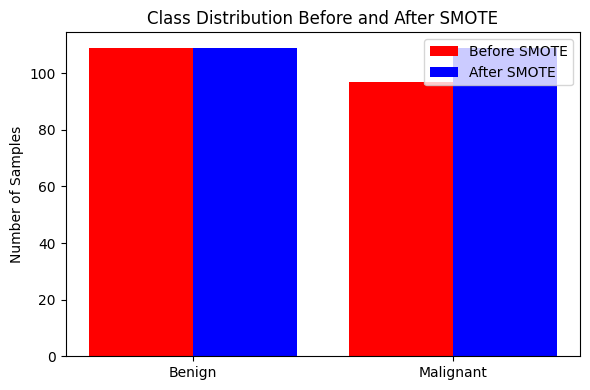

In [92]:
from collections import Counter
import matplotlib.pyplot as plt

# BEFORE SMOTE
before_counts = Counter(y_train)
print("Before SMOTE:", before_counts)

# Apply steps manually up to SMOTE
X_scaled = pipe.named_steps['scaler'].fit_transform(X_train)
X_power  = pipe.named_steps['power'].fit_transform(X_scaled)
X_pca    = pipe.named_steps['pca'].fit_transform(X_power)

X_smote, y_smote = pipe.named_steps['smote'].fit_resample(X_pca, y_train)
after_counts = Counter(y_smote)
print("After SMOTE:", after_counts)

labels = ['Benign', 'Malignant']

before_vals = [
    before_counts.get(0, 0),
    before_counts.get(1, 0)
]

after_vals = [
    after_counts.get(0, 0),
    after_counts.get(1, 0)
]

x = range(len(labels))

plt.figure(figsize=(6,4))

plt.bar(
    x,
    before_vals,
    width=0.4,
    label='Before SMOTE',
    color='red'
)

plt.bar(
    [i + 0.4 for i in x],
    after_vals,
    width=0.4,
    label='After SMOTE',
    color='blue'
)

plt.xticks([i + 0.2 for i in x], labels)
plt.ylabel("Number of Samples")
plt.title("Class Distribution Before and After SMOTE")
plt.legend()
plt.tight_layout()
plt.show()


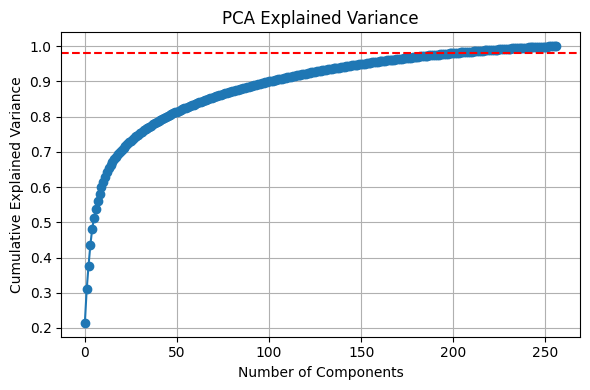

In [84]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler, PowerTransformer

scaler = RobustScaler()
power  = PowerTransformer()

X_scaled = scaler.fit_transform(X_data)
X_scaled = power.fit_transform(X_scaled)

pca = PCA().fit(X_scaled)

plt.figure(figsize=(6,4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(0.98, linestyle='--', color='r')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)
plt.tight_layout()
plt.show()


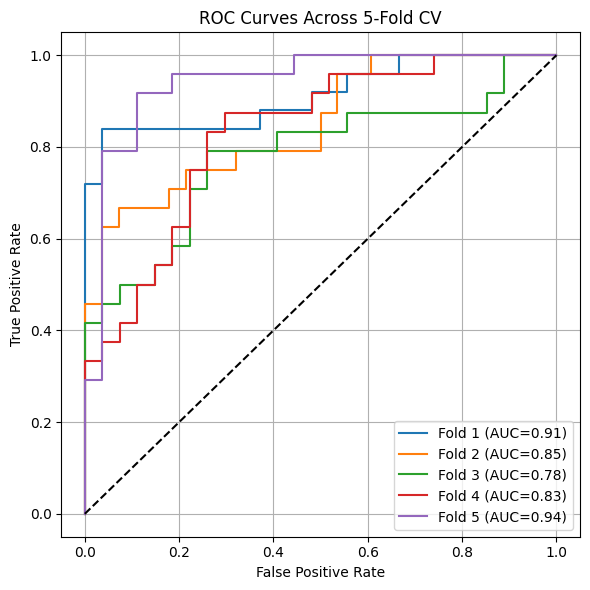

In [85]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(6,6))

for i, (train_idx, val_idx) in enumerate(skf.split(X_data, y_data)):
    X_train, X_val = X_data[train_idx], X_data[val_idx]
    y_train, y_val = y_data[train_idx], y_data[val_idx]

    best_model.fit(X_train, y_train)
    y_prob = best_model.predict_proba(X_val)[:,1]

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Fold {i+1} (AUC={roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Across 5-Fold CV")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


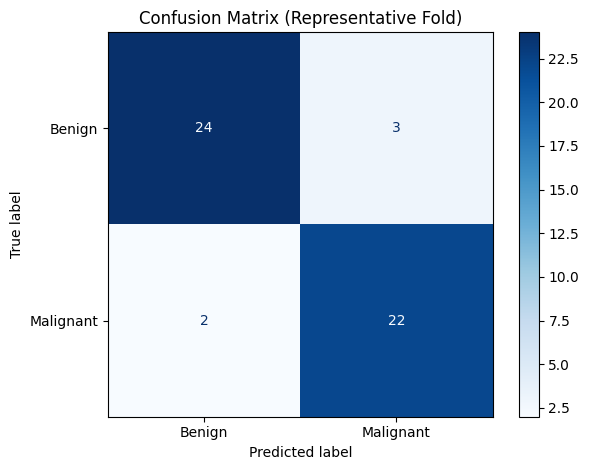

In [86]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred_opt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Representative Fold)")
plt.tight_layout()
plt.show()


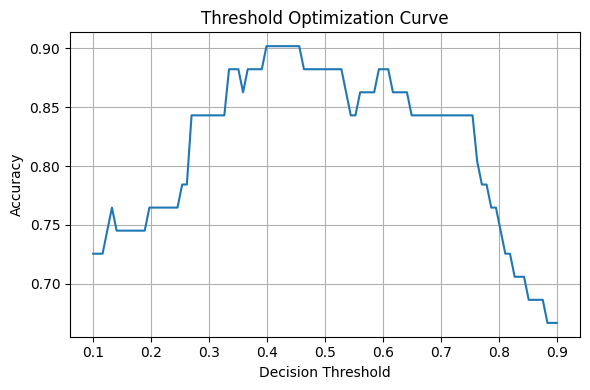

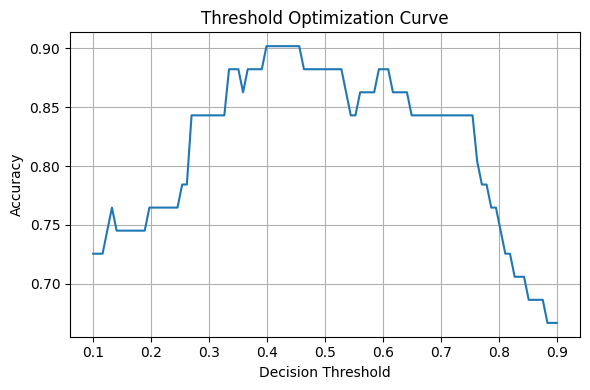

In [87]:
thresholds = np.linspace(0.1, 0.9, 100)
acc_scores = []

for t in thresholds:
    preds = (y_prob >= t).astype(int)
    acc_scores.append(accuracy_score(y_val, preds))

plt.figure(figsize=(6,4))
plt.plot(thresholds, acc_scores)
plt.xlabel("Decision Threshold")
plt.ylabel("Accuracy")
plt.title("Threshold Optimization Curve")
plt.grid(True)
plt.tight_layout()
plt.show()
thresholds = np.linspace(0.1, 0.9, 100)
acc_scores = []

for t in thresholds:
    preds = (y_prob >= t).astype(int)
    acc_scores.append(accuracy_score(y_val, preds))

plt.figure(figsize=(6,4))
plt.plot(thresholds, acc_scores)
plt.xlabel("Decision Threshold")
plt.ylabel("Accuracy")
plt.title("Threshold Optimization Curve")
plt.grid(True)
plt.tight_layout()
plt.show()


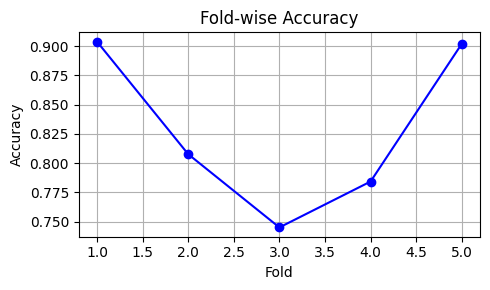

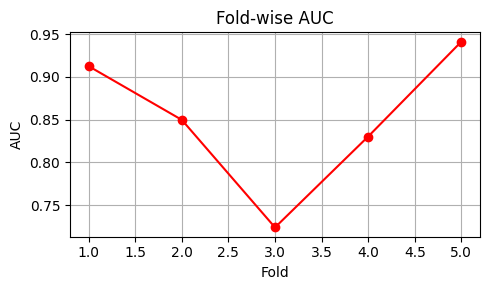

In [98]:
import matplotlib.pyplot as plt

folds = list(range(1, len(accs)+1))

plt.figure(figsize=(5,3))
plt.plot(folds, accs, marker='o', color='blue')
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Fold-wise Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5,3))
plt.plot(folds, aucs, marker='o', color='red')
plt.xlabel("Fold")
plt.ylabel("AUC")
plt.title("Fold-wise AUC")
plt.grid(True)

plt.tight_layout()
plt.show()
